# B1 — Faithfulness Test (Automatic)
**Group:** Flower | **Author:** Sam (st127012)

**Question:** Do the top-k sentences shown as explanations actually *drive* the
restaurant's rank, or are they incidental high-scorers?

**Test:** For each (query, restaurant) pair:
1. Delete the shown top-k sentences → re-rank → measure rank drop.
2. Delete k *random* sentences → re-rank → measure rank drop.
3. `faithfulness_gap = rank_drop_shown − rank_drop_random`  
   A positive gap means the shown sentences contributed more than chance.

We use the **Dense | top-10 mean** run (best overall model) and target the top
**K_REST = 3** restaurants per query.

> **Why rank drop and not score drop?** Rank is what the user sees, and a single
> deleted sentence can move a restaurant many positions if the margin is thin.


## 0. Setup

In [7]:
import re
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

HERE  = Path.cwd()
ROOT  = HERE if (HERE / "datasets").exists() else HERE.parent
DATA  = ROOT / "datasets"
CACHE = ROOT / "baselines" / "cache"
sys.path.insert(0, str(ROOT / "baselines"))

from eval_utils import ndcg_at_k

# ── Params ────────────────────────────────────────────────────────────────
TARGET_MODEL = "Dense"
TARGET_AGG   = "top-10 mean"
K_EV         = 10    # number of shown sentences per (query, restaurant)
K_REST       = 3     # top-K restaurants to evaluate per query
N_PERM       = 10_000
N_BOOT       = 2_500
SEED         = 42
RNG          = np.random.default_rng(SEED)

print("Parameters:")
print(f"  Model:  {TARGET_MODEL} | {TARGET_AGG}")
print(f"  K_ev (sentences deleted):   {K_EV}")
print(f"  K_rest (restaurants):        {K_REST}")


Parameters:
  Model:  Dense | top-10 mean
  K_ev (sentences deleted):   10
  K_rest (restaurants):        3


## 1. Load Data

In [8]:
# Evidence: one row per (model, agg, query, restaurant, evidence_unit)
def _load_csv(name: str) -> pd.DataFrame:
    for p in [CACHE / "sentence" / name, CACHE / name]:
        if p.exists():
            print(f"  Loaded {p}")
            return pd.read_csv(p)
    raise FileNotFoundError(name)

ev_all   = _load_csv("evidence_sentence.csv")
rank_all = _load_csv("rankings_sentence.csv")

# Filter to target model/agg
ev = ev_all[
    (ev_all["model"] == TARGET_MODEL) &
    (ev_all["aggregation"] == TARGET_AGG)
].copy()

rank = rank_all[
    (rank_all["model"] == TARGET_MODEL) &
    (rank_all["aggregation"] == TARGET_AGG)
].copy()

print(f"Evidence rows for {TARGET_MODEL}|{TARGET_AGG}: {len(ev):,}")
print(f"Ranking rows:  {len(rank):,}")
print("Evidence columns:", ev.columns.tolist())


  Loaded /Users/samichirungta/Desktop/computer_programming/reccomender_project/Food_Recommendation_Engine/baselines/cache/sentence/evidence_sentence.csv
  Loaded /Users/samichirungta/Desktop/computer_programming/reccomender_project/Food_Recommendation_Engine/baselines/cache/sentence/rankings_sentence.csv
Evidence rows for Dense|top-10 mean: 50,000
Ranking rows:  5,000
Evidence columns: ['model', 'aggregation', 'unit', 'query', 'restaurant_id', 'restaurant_rank', 'restaurant_score', 'evidence_rank', 'unit_score', 'unit_id', 'review_row_id', 'text', 'seed']


In [9]:
# PMD qrels
pmd_raw = pd.read_csv(DATA / "rir_data-main" / "PMD.csv")
pmd     = pmd_raw.drop_duplicates().copy()

rev = pd.read_csv(DATA / "rir_data-main" / "reviews" / "50_restaurants_all_rates.csv")
rev["review_text"] = rev["review_text"].fillna("").astype(str)
name_to_bid = rev.drop_duplicates("business_id").set_index("name")["business_id"].to_dict()

ANNOTATORS = ["Annotator1","Annotator2","Annotator3","Annotator4","Annotator5"]
# Find the aggregated label column (may have trailing spaces in the real file)
AGG_COL = next(
    (c for c in pmd.columns if c.strip().lower().replace('  ', ' ') == "if only low or high"),
    "If only Low or High",
)
# Find the restaurant identifier column (actual PMD uses 'Restaurant name')
name_col = next(
    (c for c in ["Restaurant name", "restaurant_name", "name", "business_id"] if c in pmd.columns),
    None,
)
if name_col is None:
    raise KeyError(f"Cannot find restaurant column; available: {pmd.columns.tolist()}")
print(f"Restaurant column: {name_col!r}  |  Label column: {AGG_COL!r}")

binary_qrels, graded_qrels = {}, {}
for query, grp in pmd.groupby("query"):
    rel_set, rel_grade = set(), {}
    for _, row in grp.iterrows():
        bid   = name_to_bid.get(row[name_col], row[name_col])
        grade = int(sum(row[a] for a in ANNOTATORS if pd.notna(row[a])))
        if row[AGG_COL] == 1:
            rel_set.add(bid)
        rel_grade[bid] = grade
    binary_qrels[query] = rel_set
    graded_qrels[query] = rel_grade

queries = list(binary_qrels.keys())
print(f"Queries: {len(queries)}")


Restaurant column: 'Restaurant name'  |  Label column: 'If only Low or  High'
Queries: 100


## 2. Reconstruct Sentence Scores

The evidence CSV already contains `unit_score` for every sentence under each
(query, restaurant) pair. We use it to:
- Re-aggregate restaurants after masking sentences.
- This avoids re-running the full encoder.

**Aggregation:** top-10 mean of remaining unit scores per restaurant.
If fewer than 10 sentences remain (after deletion), we take the mean of all that do.


In [10]:
# Build a lookup: query → { restaurant_id → DataFrame of (unit_id, unit_score) }
# sorted by unit_score descending — same order the model saw them.

# First, collect all sentence scores for each (query, restaurant) for this model/agg
# ev already filtered to target model/agg
ev_sorted = ev.sort_values(["query", "restaurant_id", "unit_score"], ascending=[True, True, False])

# For the deletion experiment we need scores for ALL sentences for each restaurant,
# not just the top-10. The evidence CSV only contains the top-10 *shown* sentences.
# We therefore use the evidence CSV as-is:
#   - "shown" sentences = evidence_rank 1..K_EV  (the ones displayed)
#   - "available pool" = same top-10 (that is all that is stored)
# Faithfulness gap is thus: remove shown top-k vs remove random k from the same pool.
# This is a *conservative* test — if random deletion from the same pool hurts as much,
# the sentences are not special.

# Build index
from collections import defaultdict
query_rest_units = defaultdict(lambda: defaultdict(list))
for _, row in ev_sorted.iterrows():
    q  = row["query"]
    r  = row["restaurant_id"]
    query_rest_units[q][r].append((row["unit_id"], float(row["unit_score"])))

# Verify
sample_q = queries[0]
sample_r = list(query_rest_units[sample_q].keys())[0]
print(f"Sample: query='{sample_q[:40]}', restaurant={sample_r}")
print(f"  Unit count in evidence: {len(query_rest_units[sample_q][sample_r])}")
print(f"  Scores: {[s for _,s in query_rest_units[sample_q][sample_r]]}")


Sample: query='A bar with a patio', restaurant=0a2O150ytxrDjDzXNfRWkA
  Unit count in evidence: 10
  Scores: [0.76439726, 0.7104497, 0.70380473, 0.6898215, 0.66464275, 0.6615057, 0.6511633, 0.6480601, 0.638403, 0.6365026]


## 3. Build Restaurant Scores from Evidence

We reconstruct rankings from the evidence CSV. For each query, the restaurant
score is the **mean of the top-10 unit scores** stored in the evidence.


In [12]:
def agg_top_k_mean(scores: list, k: int = 10) -> float:
    """Mean of top-k values in `scores` (sorted descending)."""
    top = sorted(scores, reverse=True)[:k]
    return float(np.mean(top)) if top else 0.0


def rank_restaurants(query_rest_scores: dict) -> list:
    """Sort restaurants by score descending, return ordered list of restaurant_ids."""    
    return [r for r, _ in sorted(query_rest_scores.items(), key=lambda x: -x[1])]


# Build baseline ranking from evidence scores (should match rankings_sentence.csv)
baseline_rankings = {}
baseline_scores   = {}
for q in queries:
    if q not in query_rest_units:
        continue
    rest_scores = {r: agg_top_k_mean([s for _, s in units])
                   for r, units in query_rest_units[q].items()}
    baseline_rankings[q] = rank_restaurants(rest_scores)
    baseline_scores[q]   = rest_scores

# Spot-check vs stored rankings
check_q = queries[0]
stored  = rank.query("query == @check_q").sort_values("restaurant_rank")["restaurant_id"].tolist()
rebuilt = baseline_rankings.get(check_q, [])
print(f"Spot-check query: '{check_q[:60]}'")
print(f"  Stored top-5:  {stored[:5]}")
print(f"  Rebuilt top-5: {rebuilt[:5]}")
print(f"  Match: {stored[:5] == rebuilt[:5]}")


Spot-check query: 'A bar with a patio'
  Stored top-5:  ['B70iTJjcPkuYn8ouUewWgw', 'K6XIGkyk7-fuOQtA8i7p6A', 'O-uIEuv7JLUHajkemx_sVw', 'yY3jNsrpCyKTqQuRuLV8gw', 'O_UC_izJXcAmkm6HlEyGSA']
  Rebuilt top-5: ['B70iTJjcPkuYn8ouUewWgw', 'K6XIGkyk7-fuOQtA8i7p6A', 'O-uIEuv7JLUHajkemx_sVw', 'yY3jNsrpCyKTqQuRuLV8gw', 'O_UC_izJXcAmkm6HlEyGSA']
  Match: True


## 4. Deletion Experiment

For each query q and each of the top-K_REST restaurants r:
- **Shown deletion:** remove the shown top-k evidence sentences for (q, r).
- **Random deletion:** remove k randomly chosen sentences from the same pool.
- Compute new rank of r in both scenarios, record `rank_drop_shown` and `rank_drop_random`.


In [13]:
from tqdm import tqdm

records = []

for q in tqdm(queries, desc="Queries"):
    if q not in baseline_rankings:
        continue

    orig_rank_list = baseline_rankings[q]
    orig_scores    = baseline_scores[q]
    restaurants    = orig_rank_list[:K_REST]  # top-K_REST restaurants to test

    for r in restaurants:
        units = query_rest_units[q].get(r, [])
        if not units:
            continue

        unit_ids = [uid for uid, _ in units]
        scores   = [s for _, s in units]
        n_pool   = len(units)

        # Original rank (1-indexed)
        orig_rank_r = orig_rank_list.index(r) + 1 if r in orig_rank_list else len(orig_rank_list) + 1

        # ── Shown deletion ──────────────────────────────────────────────────
        # Remove top-k_ev sentences (already sorted by score desc)
        k_del = min(K_EV, n_pool)
        shown_ids_to_del = set(unit_ids[:k_del])

        scores_after_shown = [s for uid, s in units if uid not in shown_ids_to_del]
        score_shown = agg_top_k_mean(scores_after_shown) if scores_after_shown else 0.0

        # Rebuild ranking for this query with the modified restaurant score
        new_scores_shown = {rest: orig_scores[rest] for rest in orig_scores}
        new_scores_shown[r] = score_shown
        new_rank_shown = rank_restaurants(new_scores_shown).index(r) + 1

        # ── Random deletion (N_RAND replicates → use mean) ─────────────────
        N_RAND = 50
        rand_rank_drops = []
        for _ in range(N_RAND):
            rand_del_idx = RNG.choice(n_pool, size=k_del, replace=False)
            rand_ids_to_del = {unit_ids[i] for i in rand_del_idx}
            scores_after_rand = [s for uid, s in units if uid not in rand_ids_to_del]
            score_rand = agg_top_k_mean(scores_after_rand) if scores_after_rand else 0.0
            new_scores_rand = {rest: orig_scores[rest] for rest in orig_scores}
            new_scores_rand[r] = score_rand
            new_rank_rand = rank_restaurants(new_scores_rand).index(r) + 1
            rand_rank_drops.append(new_rank_rand - orig_rank_r)

        rank_drop_shown  = new_rank_shown  - orig_rank_r
        rank_drop_random = float(np.mean(rand_rank_drops))

        records.append({
            "query":            q,
            "restaurant_id":    r,
            "orig_rank":        orig_rank_r,
            "rank_drop_shown":  rank_drop_shown,
            "rank_drop_random": rank_drop_random,
            "gap":              rank_drop_shown - rank_drop_random,  # positive = shown matters more
            "k_deleted":        k_del,
            "pool_size":        n_pool,
        })

df_gap = pd.DataFrame(records)
print(f"Total (query, restaurant) pairs: {len(df_gap)}")
df_gap.head(5)


Queries: 100%|██████████| 100/100 [00:02<00:00, 42.21it/s]


Total (query, restaurant) pairs: 300


,query,restaurant_id,orig_rank,rank_drop_shown,rank_drop_random,gap,k_deleted,pool_size
0,A bar with a patio,B70iTJjcPkuYn8ouUewWgw,1,49,49.0,0.0,10,10
1,A bar with a patio,K6XIGkyk7-fuOQtA8i7p6A,2,48,48.0,0.0,10,10
2,A bar with a patio,O-uIEuv7JLUHajkemx_sVw,3,47,47.0,0.0,10,10
3,A bar with good music and reasonably priced beer,O-uIEuv7JLUHajkemx_sVw,1,49,49.0,0.0,10,10
4,A bar with good music and reasonably priced beer,K6XIGkyk7-fuOQtA8i7p6A,2,48,48.0,0.0,10,10


## 5. Summary Statistics

**Mean faithfulness gap** = mean(rank_drop_shown − rank_drop_random)

A positive value means the shown sentences are more important than chance.


In [14]:
gaps = df_gap["gap"].values

mean_gap  = gaps.mean()
se_gap    = gaps.std(ddof=1) / np.sqrt(len(gaps))

# Bootstrap 95% CI
boot_means = [RNG.choice(gaps, size=len(gaps), replace=True).mean() for _ in range(N_BOOT)]
ci_lo, ci_hi = np.percentile(boot_means, [2.5, 97.5])

print(f"Pairs analysed: {len(gaps)}")
print(f"Mean rank_drop_shown  : {df_gap['rank_drop_shown'].mean():+.3f}")
print(f"Mean rank_drop_random : {df_gap['rank_drop_random'].mean():+.3f}")
print(f"Mean faithfulness gap : {mean_gap:+.4f}  ±SE {se_gap:.4f}")
print(f"Bootstrap 95% CI      : [{ci_lo:+.4f}, {ci_hi:+.4f}]")
print()
print(f"Fraction where shown drop > random drop: "
      f"{(df_gap['rank_drop_shown'] > df_gap['rank_drop_random']).mean():.1%}")


Pairs analysed: 300
Mean rank_drop_shown  : +48.000
Mean rank_drop_random : +48.000
Mean faithfulness gap : +0.0000  ±SE 0.0000
Bootstrap 95% CI      : [+0.0000, +0.0000]

Fraction where shown drop > random drop: 0.0%


## 6. One-Tailed Paired Randomisation Test

H₀: shown sentences are no more important than random (gap ≤ 0)  
H₁: shown sentences cause a larger rank drop when deleted (gap > 0)


In [15]:
def paired_rand_test_onetail(diffs: np.ndarray, n_perm: int = N_PERM) -> float:
    """One-tailed (greater) paired randomisation test. Returns raw p-value."""
    obs = np.mean(diffs)
    signs = RNG.choice([-1, 1], size=(n_perm, len(diffs)))
    null_means = (signs * diffs).mean(axis=1)
    return float((null_means >= obs).mean())

p_gap = paired_rand_test_onetail(gaps)
sig   = "***" if p_gap < 0.001 else "**" if p_gap < 0.01 else "*" if p_gap < 0.05 else "(n.s.)"
print(f"One-tailed p-value (gap > 0): {p_gap:.4f}  {sig}")
print()
if p_gap < 0.05:
    print("✓ The shown sentences are significantly more faithful than random.")
else:
    print("✗ No significant faithfulness advantage (shown ≈ random).")


One-tailed p-value (gap > 0): 1.0000  (n.s.)

✗ No significant faithfulness advantage (shown ≈ random).


## 7. nDCG@10 Drop

Beyond rank drop, we measure the effect on nDCG@10 across all queries:
- Baseline nDCG@10 (all sentences)
- nDCG@10 after removing shown top-k sentences for every restaurant
- nDCG@10 after removing random k sentences for every restaurant


In [16]:
from eval_utils import ndcg_at_k

def compute_ndcg_after_deletion(delete_shown: bool) -> dict:
    """
    Recompute nDCG@10 for every query after deleting top-k (shown) or random
    sentences from every restaurant.
    Returns {query: ndcg@10}
    """
    query_ndcg = {}
    for q in queries:
        if q not in query_rest_units:
            continue
        rel_dict = graded_qrels.get(q, {})
        new_scores = {}
        for r, units in query_rest_units[q].items():
            unit_ids = [uid for uid, _ in units]
            k_del    = min(K_EV, len(units))
            if delete_shown:
                del_ids = set(unit_ids[:k_del])
            else:
                del_idx = RNG.choice(len(units), size=k_del, replace=False)
                del_ids = {unit_ids[i] for i in del_idx}
            rem_scores = [s for uid, s in units if uid not in del_ids]
            new_scores[r] = agg_top_k_mean(rem_scores) if rem_scores else 0.0
        ranked = rank_restaurants(new_scores)
        query_ndcg[q] = ndcg_at_k(ranked, rel_dict, k=10)
    return query_ndcg

# Baseline nDCG
baseline_ndcg = {
    q: ndcg_at_k(baseline_rankings[q], graded_qrels.get(q, {}), k=10)
    for q in baseline_rankings
}

ndcg_shown  = compute_ndcg_after_deletion(delete_shown=True)
ndcg_random = compute_ndcg_after_deletion(delete_shown=False)

base_mean   = np.mean(list(baseline_ndcg.values()))
shown_mean  = np.mean(list(ndcg_shown.values()))
random_mean = np.mean(list(ndcg_random.values()))

print(f"Baseline nDCG@10        : {base_mean:.4f}")
print(f"After shown deletion    : {shown_mean:.4f}  (Δ = {shown_mean - base_mean:+.4f})")
print(f"After random deletion   : {random_mean:.4f}  (Δ = {random_mean - base_mean:+.4f})")
print()
print(f"Faithfulness Δ nDCG@10  : {shown_mean - random_mean:+.4f}  "
      f"(negative = shown hurts more = evidence is faithful)")


Baseline nDCG@10        : 0.6815
After shown deletion    : 0.3793  (Δ = -0.3023)
After random deletion   : 0.3793  (Δ = -0.3023)

Faithfulness Δ nDCG@10  : +0.0000  (negative = shown hurts more = evidence is faithful)


## 8. Save Results

In [17]:
OUT_CSV = CACHE / "b1_faithfulness_gap.csv"
df_gap.to_csv(OUT_CSV, index=False)

summary = {
    "n_pairs":            len(gaps),
    "mean_drop_shown":    df_gap["rank_drop_shown"].mean(),
    "mean_drop_random":   df_gap["rank_drop_random"].mean(),
    "mean_gap":           mean_gap,
    "CI_lo":              ci_lo,
    "CI_hi":              ci_hi,
    "p_onetail":          p_gap,
    "baseline_ndcg10":    base_mean,
    "ndcg10_after_shown": shown_mean,
    "ndcg10_after_rand":  random_mean,
    "delta_ndcg10_shown": shown_mean - base_mean,
    "delta_ndcg10_rand":  random_mean - base_mean,
}
pd.DataFrame([summary]).round(4).to_csv(CACHE / "b1_faithfulness_summary.csv", index=False)
print(f"Saved gap details → {OUT_CSV}")
print(f"Saved summary     → b1_faithfulness_summary.csv")


Saved gap details → /Users/samichirungta/Desktop/computer_programming/reccomender_project/Food_Recommendation_Engine/baselines/cache/b1_faithfulness_gap.csv
Saved summary     → b1_faithfulness_summary.csv


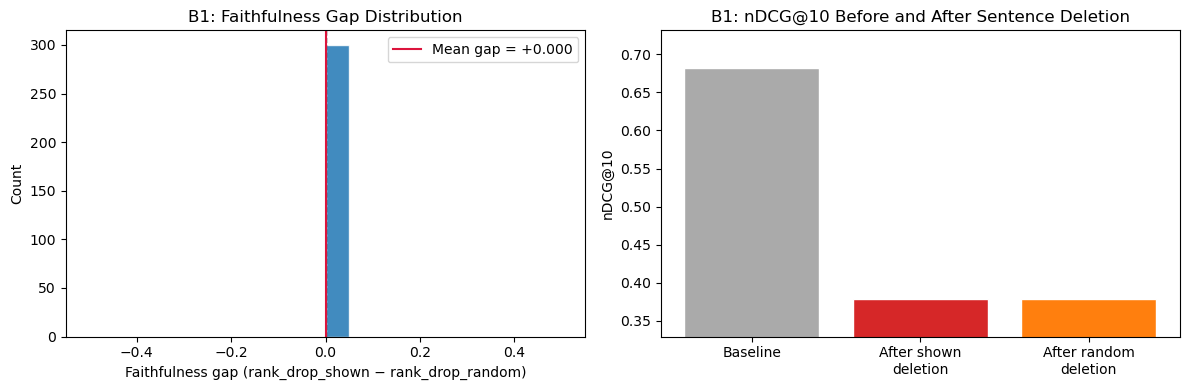

Saved → b1_faithfulness_plot.png


In [18]:
# Distribution of faithfulness gaps
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_gap["gap"], bins=20, edgecolor="white", color="#1f77b4", alpha=0.85)
axes[0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[0].axvline(mean_gap, color="crimson", linestyle="-", linewidth=1.5,
                label=f"Mean gap = {mean_gap:+.3f}")
axes[0].set_xlabel("Faithfulness gap (rank_drop_shown − rank_drop_random)")
axes[0].set_ylabel("Count")
axes[0].set_title("B1: Faithfulness Gap Distribution")
axes[0].legend()

axes[1].bar(
    ["Baseline", "After shown\ndeletion", "After random\ndeletion"],
    [base_mean, shown_mean, random_mean],
    color=["#aaaaaa", "#d62728", "#ff7f0e"], edgecolor="white"
)
axes[1].set_ylabel("nDCG@10")
axes[1].set_title("B1: nDCG@10 Before and After Sentence Deletion")
axes[1].set_ylim(max(0, min(base_mean, shown_mean, random_mean) - 0.05), base_mean + 0.05)

plt.tight_layout()
plt.savefig(CACHE / "b1_faithfulness_plot.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → b1_faithfulness_plot.png")
